In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [4]:
df = pd.read_csv('placement.csv')
df.head()

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


Text(0, 0.5, 'Package in LPA')

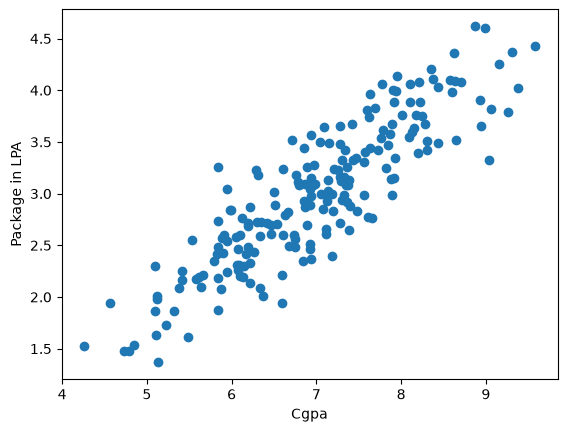

In [7]:
plt.scatter(df['cgpa'] , df['package'])
plt.xlabel('Cgpa')
plt.ylabel('Package in LPA')

In [8]:
from sklearn.model_selection import train_test_split

In [9]:
X = df[['cgpa']]
y = df['package']

In [10]:
X_train , X_test , y_train , y_test = train_test_split(X, y , test_size = 0.2 , random_state=2)

In [12]:
X_train.head()

,cgpa
137,7.14
163,8.93
111,5.42
123,5.10
109,7.77


In [13]:
from sklearn.linear_model import LinearRegression

In [14]:
lr = LinearRegression()

In [15]:
lr.fit(X_train , y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.56]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['cgpa']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.8961
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [16]:
lr.coef_

array([0.55795197])

In [18]:
lr.intercept_

np.float64(-0.8961119222429126)

In [28]:
y_pred = lr.predict(X_test)
y_pred

array([3.89111601, 3.09324469, 2.38464568, 2.57434935, 1.6537286 ,
       1.77647803, 2.07219258, 2.93143862, 3.76278706, 2.93701814,
       4.09197872, 3.51170867, 2.97049525, 2.40138424, 3.18809652,
       3.46707251, 1.94386362, 3.24389172, 2.97607477, 3.41685683,
       2.55761079, 3.16577844, 2.85890486, 3.12114229, 3.68467378,
       2.8700639 , 3.49497011, 3.34432308, 3.91901361, 1.96060218,
       3.65119666, 3.2104146 , 3.74046898, 2.7863711 , 2.78079158,
       3.27178932, 3.52844723, 2.61340599, 2.65804215, 2.71383735])

In [ ]:
# MAE = Mean Absolute Error

# MAE = 1/n * sum(yi - y^)    for each row
# OR
# MAE = mean(yi - y^)

In [29]:
y_test.values

array([4.1 , 3.49, 2.08, 2.33, 1.94, 1.48, 1.86, 3.09, 4.21, 2.87, 3.65,
       4.  , 2.89, 2.6 , 2.99, 3.25, 1.86, 3.67, 2.37, 3.42, 2.48, 3.65,
       2.6 , 2.83, 4.08, 2.56, 3.58, 3.81, 4.09, 2.01, 3.63, 2.92, 3.51,
       1.94, 2.21, 3.34, 3.34, 3.23, 2.01, 2.61])

In [42]:
# By own hardcoded formula

print('MAE :' , np.mean(np.abs(y_test.values - y_pred)))

MAE : 0.2884710931878175


In [35]:
from sklearn.metrics import mean_absolute_error

In [43]:
# By sklearn function

print('MAE :',mean_absolute_error(y_test , y_pred))

MAE : 0.2884710931878175


In [ ]:
# MSE = Mean squared error

# MSE = mean of (y_test - y_pred)**2

In [44]:
from sklearn.metrics import mean_squared_error

In [46]:
# By sklearn function

print('MSE : ', mean_squared_error(y_test , y_pred))

MSE :  0.12129235313495527


In [48]:
y_test.values

array([4.1 , 3.49, 2.08, 2.33, 1.94, 1.48, 1.86, 3.09, 4.21, 2.87, 3.65,
       4.  , 2.89, 2.6 , 2.99, 3.25, 1.86, 3.67, 2.37, 3.42, 2.48, 3.65,
       2.6 , 2.83, 4.08, 2.56, 3.58, 3.81, 4.09, 2.01, 3.63, 2.92, 3.51,
       1.94, 2.21, 3.34, 3.34, 3.23, 2.01, 2.61])

In [49]:
y_pred

array([3.89111601, 3.09324469, 2.38464568, 2.57434935, 1.6537286 ,
       1.77647803, 2.07219258, 2.93143862, 3.76278706, 2.93701814,
       4.09197872, 3.51170867, 2.97049525, 2.40138424, 3.18809652,
       3.46707251, 1.94386362, 3.24389172, 2.97607477, 3.41685683,
       2.55761079, 3.16577844, 2.85890486, 3.12114229, 3.68467378,
       2.8700639 , 3.49497011, 3.34432308, 3.91901361, 1.96060218,
       3.65119666, 3.2104146 , 3.74046898, 2.7863711 , 2.78079158,
       3.27178932, 3.52844723, 2.61340599, 2.65804215, 2.71383735])

In [54]:
# By own hardcoded formula

print('MSE : ',np.mean((y_test.values - y_pred)**2))

MSE :  0.12129235313495527


In [ ]:
# RMSE = Root mean squared error

# Root of mse

In [55]:
from sklearn.metrics import root_mean_squared_error

In [58]:
# By sklearn function

print('RMSE : ', root_mean_squared_error(y_test , y_pred))

RMSE :  0.34827051717731616


In [64]:
# By own hardcoded formula

print('RMSE : ', (np.mean((y_test.values - y_pred)**2))**0.5)

RMSE :  0.34827051717731616


In [ ]:
# R2 Score

# 1 - SSres/SStotal

# SSres = sum of (y_test - y_pred)**2
# SStotal = sum of (y_test - y_mean)**2

In [66]:
from sklearn.metrics import r2_score

In [68]:
# By sklearn function

print('R2 score : ' , r2_score(y_test , y_pred))

R2 score :  0.780730147510384


In [79]:
# By own hardcoded formula

SSr = np.sum((y_test.values - y_pred)**2)
print('SS residual :',SSr)

SS residual : 4.851694125398211


In [76]:
SSt = np.sum((y_test.values - np.mean(y_test))**2)
print('SS total :',SSt)

SS total : 22.12659


In [80]:
my_r2 = 1 - (SSr / SSt)
print('R2 score :',my_r2)

R2 score : 0.780730147510384


In [83]:
# Adjusted R2 score

# adR2 = 1 - [((1-R2score)(n-1)) / (n - k - 1)]

# n = number of rows
# k = no. of independent variable(input columns)

In [84]:
my_r2

np.float64(0.780730147510384)

In [91]:
n = 40
k = 1
adR2 = 1 - (((1 - my_r2)*(n-1)) / (n-k-1))

In [93]:
print('Adjusted R2 score :',adR2)

Adjusted R2 score : 0.7749598882343415


In [94]:
# Now the intresting part

# Note down the R2 score and adjusted r2 score 
# R2 = 0.780730147510384    
# Adjusted R2 score : 0.7749598882343415

# We are going to find that if i add a useless column in the data whether 
# the r2 score increases or not and also adjusted r2 increases or not

In [134]:
new_df1 = df.copy()
new_df1['random_feature'] = np.random.random(200)

new_df1 = new_df1[['cgpa','random_feature','package']]
new_df1.head()

,cgpa,random_feature,package
0,6.89,0.179960,3.26
1,5.12,0.354596,1.98
2,7.82,0.904354,3.25
3,7.42,0.747777,3.67
4,6.94,0.470608,3.57


Text(0, 0.5, 'Package(in lpa)')

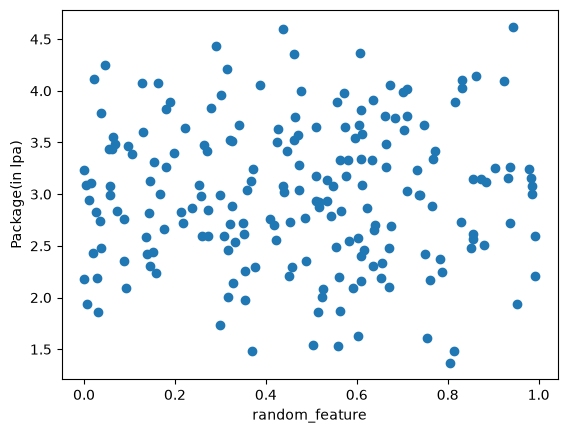

In [135]:
# useless column which is not useful for the data

plt.scatter(new_df1['random_feature'],new_df1['package'])
plt.xlabel('random_feature')
plt.ylabel('Package(in lpa)')

In [136]:
from sklearn.model_selection import train_test_split

In [137]:
X = new_df1.iloc[:,0:2]
y = new_df1.iloc[:,-1]

In [138]:
X_train , X_test , y_train , y_test =  train_test_split(X,y , test_size=0.2 , random_state=2)

In [139]:
from sklearn.linear_model import LinearRegression

In [140]:
lr = LinearRegression()

In [141]:
lr.fit(X_train , y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[ 0.56,-0.01]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['cgpa','random_feature']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.89
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [142]:
y_pred = lr.predict(X_test)

In [143]:
from sklearn.metrics import r2_score

In [144]:
my_r2 = r2_score(y_test , y_pred)
print('R2 score of new_df1 :', r2_score(y_test , y_pred))

R2 score of new_df1 : 0.7814251011781679


In [145]:
n = 40
k = 2
adR2 = 1 - (((1 - my_r2)*(n-1)) / (n-k-1))

In [147]:
print('Adjusted R2 score :',adR2)

Adjusted R2 score : 0.7696102417823931


In [121]:
# The new R2 and adjusted r2 are 

# R2 score  : 0.7809286244603255             (still increased even useless column is added)
# Adjusted R2 score : 0.7696102417823931     (decreased when useless column is added)

# Old scores are 

# R2 = 0.780730147510384    
# Adjusted R2 score : 0.7749598882343415

In [ ]:
# Now  going to add a usefull column to see the scores

In [148]:

new_df2 = df.copy()

new_df2['iq'] = new_df2['package'] + (np.random.randint(-12,12,200)/10)

new_df2 = new_df2[['cgpa','iq','package']]

In [149]:
new_df2.sample(5)

,cgpa,iq,package
106,6.13,2.69,2.19
83,8.44,2.49,3.49
97,5.98,1.74,2.84
86,7.61,1.67,2.77
45,7.87,2.68,3.58


Text(0, 0.5, 'Package(in lpa)')

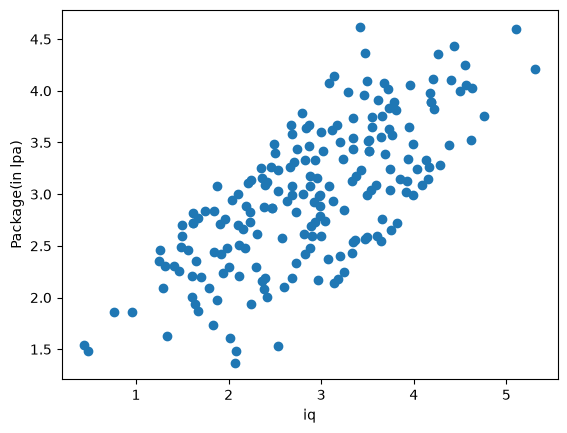

In [150]:
# This one is looking a useful data 
plt.scatter(new_df2['iq'],new_df2['package'])
plt.xlabel('iq')
plt.ylabel('Package(in lpa)')

In [151]:
np.random.randint(-100,100)


82

In [152]:
X = new_df2.iloc[:,0:2]
y = new_df2.iloc[:,-1]

In [153]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [154]:
lr = LinearRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)

In [155]:
my_r2 = r2_score(y_test,y_pred)
print("R2 score",r2_score(y_test,y_pred))


R2 score 0.8298241782530018


In [156]:
n = 40
k = 2
adR2 = 1 - (((1 - my_r2)*(n-1)) / (n-k-1))

In [157]:
print('Adjusted r2 score :',adR2)

Adjusted r2 score : 0.8206254851855965


In [158]:
# The new R2 and adjusted r2 are 

# R2 score  : 0.8298241782530018             (still increased even useful column is added)
# Adjusted R2 score : 0.8206254851855965     (it only incraeses when we add a useful column)

# Old scores are 

# R2 = 0.780730147510384    
# Adjusted R2 score : 0.7749598882343415